# 10 — Open set: flagging a signal that belongs to none of the hypotheses

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**Why this notebook.** In notebook 06 every method *detected* a burst of band-limited stochastic noise (belonging to none of the three families) and assigned it a family, mostly sine-Gaussian: a softmax is normalised over the classes it knows, and the posterior of the Bayesian classifier over the families it contains. None of the methods could say "none of the above". Here that limitation is tested directly with two kinds of **out-of-distribution** signals injected at the same SNR as in-family ones:
* a Gaussian-enveloped **stochastic burst** (σ_t = 15 ms) — the signal of notebook 06;
* a **binary-black-hole (IMRPhenomD) signal** of notebook 08: a real chirp that is *not* one of the three phenomenological families.

**What it does**
1. **Goodness-of-fit of the matched filter.** Fit the three families (best template, lag, complex amplitude), subtract the best fit and test the energy of the **residual** in the whitened series around the fitted time: a signal that the family describes leaves only noise; one that it does not leaves excess power.
2. **Open-set scores of the 4-class CNN** (notebook 06: static data; notebook 07: fresh injections): maximum softmax probability among the signal classes, the energy score $-\log\sum e^{z_c}$ and the **Mahalanobis distance** of the penultimate-layer features from the in-family class means.
3. Compares them by the AUROC of separating in-family from out-of-family detected signals, and by the fraction of out-of-family signals flagged at 5 % of in-family signals wrongly flagged.

**What it does not do**: no parameter estimation, no retraining with an explicit "unknown" class, no calibration of a flagging threshold for a search; the networks were trained **without** IMR signals, which is the point of the IMR test.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import logsumexp, softmax
import seq_models as sm
import open_set as osm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
CH, data, S1, DS = sm.load_data()
vva, cva = data["val"]; vte, cte = data["test"]; S1te = S1["test"]
TEST = sm.make_test_sets(data, S1); SNRS_O = (8, 12, 16)
BANKS = {i: [osm.FamilyBank(k, CH[i]["S1"]) for k in g.MORPHS] for i in CH}
summary = {}

## 1. Models and test sets

4-class CNNs: the two seeds of notebook 06 (trained on the static set) and the two of `cnn4_fresh` (notebook 07 machinery: fresh injections at every epoch). All receive the same test windows: 1500 in-family signals per SNR (500 per morphology, the test sets of notebooks 05–08) and 1500 signals of each out-of-family type; 600 are used for the validation-noise detection threshold.

In [2]:
def load_mc(static, s):
    if static:
        m = sm.builder(dict(arch="cnn", nout=4), s); m.load_weights(os.path.join(sm.MODELS, f"cnn_mc_s{s}.weights.h5")); return m
    return sm.train_variant("cnn4_fresh", None, None, seed=s, verbose=False)[0]
MODELS4 = {"static": [load_mc(True, s) for s in (0, 1)], "fresh": [load_mc(False, s) for s in (0, 1)]}
def logits4(group, v): return np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024) for m in MODELS4[group]], 0)

def stochastic_burst(v, snr, r, sigma=0.015):
    t = np.arange(g.NWIN) / g.FS; t0 = r.uniform(0.3, 0.7, (len(v), 1))
    w = r.normal(size=v.shape) * np.exp(-0.5 * ((t[None] - t0) / sigma) ** 2)
    X = g.to_bins(w); w = g.to_series(X * (snr / g.snr_of(X))[:, None]); return v + w

r = np.random.default_rng(1010); SETS = {}
for snr in SNRS_O:
    SETS[("in", snr)] = (np.concatenate([TEST[(k, snr)][0] for k in g.MORPHS]), np.concatenate([TEST[(k, snr)][1] for k in g.MORPHS]))
    ii = r.choice(len(vte), 1500, replace=False); SETS[("stoch", snr)] = (stochastic_burst(vte[ii], float(snr), r), cte[ii])
    ii = r.choice(len(vte), 1500, replace=False); SETS[("imr", snr)] = (g.inject(vte[ii], "imr_test", float(snr), r, S1te[ii])[0], cte[ii])
print({k: len(v[0]) for k, v in SETS.items()})

{('in', 8): 1500, ('stoch', 8): 1500, ('imr', 8): 1500, ('in', 12): 1500, ('stoch', 12): 1500, ('imr', 12): 1500, ('in', 16): 1500, ('stoch', 16): 1500, ('imr', 16): 1500}


## 2. Goodness-of-fit of the matched filter

Residual energy of the best-fitting family in ±60 ms around the fitted time (123 samples; noise gives ≈ 113 with fluctuations of a few units), for a noise window and for in-family and out-of-family signals at ρ = 12.

goodness-of-fit scores: 94 s


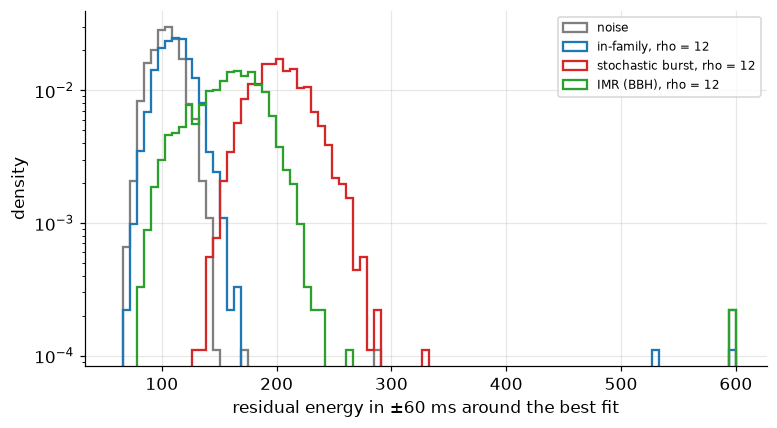

median residual energy:  {"('in', 8)": 107.7, "('stoch', 8)": 143.7, "('imr', 8)": 126.8, "('in', 12)": 111.4, "('stoch', 12)": 202.5, "('imr', 12)": 161.6, "('in', 16)": 114.3, "('stoch', 16)": 281.3, "('imr', 16)": 210.5, 'noise': 103.8}


In [3]:
def gof(series, cid):
    out = np.zeros(len(series)); fam = np.zeros(len(series), int); rho2 = np.zeros(len(series))
    for c in np.unique(cid):
        m = cid == c; o = osm.fit_best_family(g.to_bins(series[m]), BANKS[c]); out[m] = o["E_loc"]; fam[m] = o["family"]; rho2[m] = o["rho2"]
    return out, fam, rho2
t0_ = time.time()
GOF = {k: gof(*v) for k, v in SETS.items()}; GOF["noise"] = gof(vte[:1500], cte[:1500])
print("goodness-of-fit scores: %.0f s" % (time.time() - t0_))
fig, ax = plt.subplots(figsize=(8, 4.2)); bins = np.linspace(60, 600, 90)
for lab, key, c in (("noise", "noise", "#7f7f7f"), ("in-family, rho = 12", ("in", 12), g.COLORS["freq"]), ("stochastic burst, rho = 12", ("stoch", 12), g.COLORS["bayes"]), ("IMR (BBH), rho = 12", ("imr", 12), g.COLORS["ml"])):
    ax.hist(np.clip(GOF[key][0], 60, 599), bins=bins, histtype="step", density=True, color=c, lw=1.5, label=lab)
ax.set_yscale("log"); ax.set_xlabel("residual energy in ±60 ms around the best fit"); ax.set_ylabel("density"); ax.legend(fontsize=8)
g.savefig(fig, "fig10_gof_distributions"); plt.show()
print("median residual energy: ", {str(k): round(float(np.median(v[0])), 1) for k, v in GOF.items()})

## 3. Open-set scores of the networks

For a 4-class network with logits $z_0$ (noise), $z_{1..3}$ (signal classes): **MSP** = the largest softmax probability among the signal classes after renormalising over them (a confident network → low out-of-distribution score $1-\mathrm{MSP}$); **energy** = $-\log\sum_c e^{z_c}$ (low for inputs resembling the training data); **Mahalanobis** = the smallest squared distance, in the 32-dimensional penultimate layer, to the three in-family class means with a shared covariance fitted on training signals of SNR ≥ 6.

In [4]:
def feature_model(m): return keras.Model(m.inputs, m.layers[-3].output)         # output of the Dense(32) layer
class Mahalanobis:
    def __init__(self, m, X, y):
        self.fm = feature_model(m); F = self.fm.predict(X, verbose=0, batch_size=1024)
        self.mu = np.stack([F[y == c].mean(0) for c in (1, 2, 3)]); Fc = np.concatenate([F[y == c] - self.mu[c - 1] for c in (1, 2, 3)])
        self.P = np.linalg.pinv(np.cov(Fc.T) + 1e-6 * np.eye(F.shape[1]))
    def score(self, v):
        F = self.fm.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024); d = F[:, None, :] - self.mu[None]
        return np.einsum("nki,ij,nkj->nk", d, self.P, d).min(1)
# fit on in-family training signals with snr >= 6 (the signal half of the training set)
ntr = len(DS["train"]["noise"]); sel = np.where((DS["train"]["y4"][ntr:] > 0) & (DS["train"]["snr"] >= 6))[0][:6000] + ntr
MAH = {"fresh": [Mahalanobis(m, DS["train"]["X"][sel], DS["train"]["y4"][sel]) for m in MODELS4["fresh"]],
       "static": [Mahalanobis(m, DS["train"]["X"][sel], DS["train"]["y4"][sel]) for m in MODELS4["static"]]}
def net_scores(group, v):
    z = logits4(group, v); zs = z[:, 1:]; p = softmax(zs, axis=1)
    return {"1 - MSP": 1 - p.max(1), "energy": -logsumexp(z, axis=1), "Mahalanobis": np.mean([m.score(v) for m in MAH[group]], 0), "detect": logsumexp(zs, axis=1) - z[:, 0]}
NET = {(group, k): net_scores(group, v) for group in ("static", "fresh") for k, (v, c) in SETS.items()}
NETVAL = {group: net_scores(group, vva)["detect"] for group in ("static", "fresh")}

## 4. Which score separates in-family from out-of-family signals?

Only **detected** signals are compared (the 4-class network's any-signal statistic above the 99 % quantile of the validation noise, FAP = 10⁻²), since the question is meaningful for a signal that is clearly there. AUROC = probability that an out-of-family signal gets a higher out-of-distribution score than an in-family one; "flagged" = fraction of out-of-family signals above the 95 % quantile of the in-family scores.

In [5]:
def evaluate(score_in, score_out):
    a = g.auc(score_in, score_out) if len(score_in) > 20 and len(score_out) > 20 else np.nan
    flag = float((score_out > np.quantile(score_in, .95)).mean()) if len(score_in) > 20 and len(score_out) > 0 else np.nan
    return a, flag
rows = []
for ood, lab in (("stoch", "stochastic burst"), ("imr", "IMR (BBH) signal")):
    for snr in SNRS_O:
        for group in ("static", "fresh"):
            thr = g.threshold_at_far(NETVAL[group], 1e-2); gi = NET[(group, ("in", snr))]["detect"] > thr; go = NET[(group, (ood, snr))]["detect"] > thr
            for name in ("1 - MSP", "energy", "Mahalanobis"):
                a, f = evaluate(NET[(group, ("in", snr))][name][gi], NET[(group, (ood, snr))][name][go])
                rows.append(dict(ood=lab, snr=snr, method=f"{name} (CNN {group})", AUROC=a, flagged_at_5pc=f, detected_in=float(gi.mean()), detected_out=float(go.mean())))
        # matched-filter residual, detected = the same gate of the fresh network (same windows)
        thr = g.threshold_at_far(NETVAL["fresh"], 1e-2); gi = NET[("fresh", ("in", snr))]["detect"] > thr; go = NET[("fresh", (ood, snr))]["detect"] > thr
        a, f = evaluate(GOF[("in", snr)][0][gi], GOF[(ood, snr)][0][go])
        rows.append(dict(ood=lab, snr=snr, method="matched-filter residual (±60 ms)", AUROC=a, flagged_at_5pc=f, detected_in=float(gi.mean()), detected_out=float(go.mean())))
res = pd.DataFrame(rows)
for lab in ("stochastic burst", "IMR (BBH) signal"):
    print(lab); display(res[res.ood == lab].pivot(index="method", columns="snr", values="AUROC").round(3).join(res[res.ood == lab].pivot(index="method", columns="snr", values="flagged_at_5pc").round(2), lsuffix=" AUROC", rsuffix=" flagged"))

stochastic burst


snr,8 AUROC,12 AUROC,16 AUROC,8 flagged,12 flagged,16 flagged
method,,,,,,
1 - MSP (CNN fresh),0.733,0.891,0.934,0.15,0.46,0.62
1 - MSP (CNN static),0.715,0.833,0.863,0.11,0.22,0.29
Mahalanobis (CNN fresh),0.882,0.805,0.612,0.59,0.50,0.24
Mahalanobis (CNN static),0.747,0.477,0.300,0.17,0.05,0.01
energy (CNN fresh),0.838,0.966,0.986,0.38,0.83,0.92
energy (CNN static),0.796,0.944,0.975,0.23,0.69,0.85
matched-filter residual (±60 ms),0.935,0.998,1.000,0.77,1.00,1.00


IMR (BBH) signal


snr,8 AUROC,12 AUROC,16 AUROC,8 flagged,12 flagged,16 flagged
method,,,,,,
1 - MSP (CNN fresh),0.910,0.967,0.981,0.47,0.81,0.91
1 - MSP (CNN static),0.851,0.921,0.938,0.28,0.47,0.56
Mahalanobis (CNN fresh),0.692,0.519,0.377,0.12,0.05,0.02
Mahalanobis (CNN static),0.672,0.517,0.408,0.05,0.01,0.01
energy (CNN fresh),0.932,0.982,0.989,0.64,0.92,0.94
energy (CNN static),0.892,0.974,0.990,0.50,0.85,0.95
matched-filter residual (±60 ms),0.793,0.903,0.925,0.37,0.75,0.81


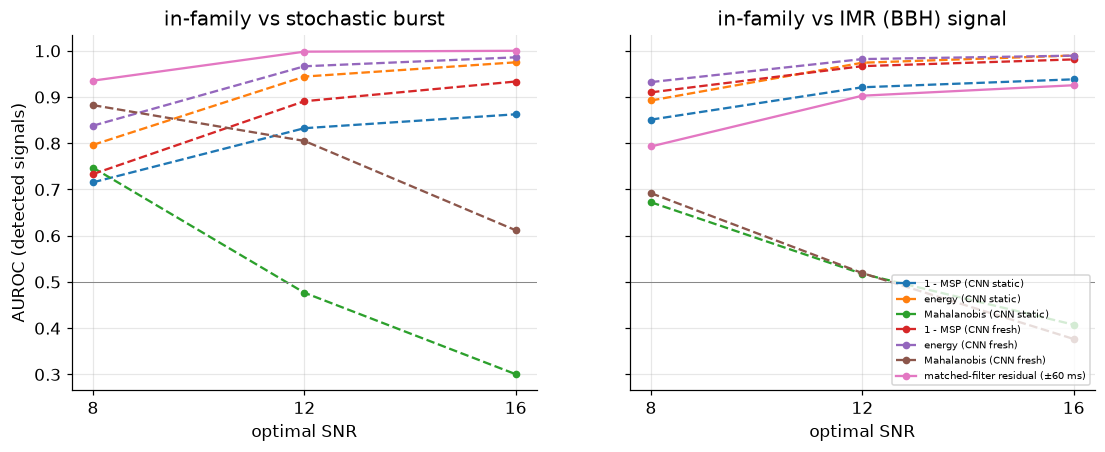

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
methods = list(res.method.unique()); cm = plt.cm.tab10(np.linspace(0, 1, 10))
for a, lab in zip(ax, ("stochastic burst", "IMR (BBH) signal")):
    for j, mth in enumerate(methods):
        d = res[(res.ood == lab) & (res.method == mth)].sort_values("snr"); a.plot(d.snr, d.AUROC, marker="o", ms=4, color=cm[j], label=mth, ls="-" if "residual" in mth else "--")
    a.axhline(.5, color="grey", lw=.6); a.set_xlabel("optimal SNR"); a.set_title(f"in-family vs {lab}"); a.set_xticks(SNRS_O)
ax[0].set_ylabel("AUROC (detected signals)"); ax[1].legend(fontsize=6.5, loc="lower right")
g.savefig(fig, "fig10_auroc"); plt.show()

In [7]:
summary.update(results=res.to_dict("records"), snrs=list(SNRS_O), median_gof={str(k): float(np.median(v[0])) for k, v in GOF.items()},
               family_called={f"{k[0]}|{k[1]}": np.bincount(v[1], minlength=3).tolist() for k, v in GOF.items() if k != "noise"})
g.save_json(summary, "10_summary.json"); print("saved")

saved



## Conclusions

Out-of-family signals injected at the same optimal SNR as the in-family ones (500 per morphology and SNR), detected signals only (the gate: any-signal statistic of the 4-class CNN above the FAP = 10⁻² threshold; 96 % of the in-family signals at ρ = 8 and 100 % at ρ ≥ 12 pass it, against 46 % of the stochastic bursts and 74 % of the IMR signals at ρ = 8).

1. **The goodness-of-fit of the matched filter solves the problem of notebook 06 for stochastic bursts.** The energy of the residual in ±60 ms around the best fit separates a stochastic burst from the in-family signals with AUROC 0.94 / 0.998 / 1.000 at ρ = 8 / 12 / 16; at 5 % of in-family signals wrongly flagged it flags 77 % of the stochastic bursts at ρ = 8 and 100 % at ρ ≥ 12. A signal that a family describes leaves only noise (median residual 108–114, noise 104); a stochastic burst leaves 144 / 202 / 281 at ρ = 8 / 12 / 16.
2. **For a binary-black-hole signal the best open-set score is the energy score of the network** (AUROC 0.93 / 0.98 / 0.99; 64 % / 92 % / 94 % flagged), followed by the maximum softmax probability of the network trained with fresh injections (0.91 / 0.97 / 0.98); the residual of the matched filter is weaker (0.79 / 0.90 / 0.93; flagging 37 % / 75 % / 81 %), because an IMR chirp is *partly* described by the chirp and sine-Gaussian families (the fit is called a sine-Gaussian or a chirp in 99 % of the cases): its residual is smaller than that of a signal that is noise-like.
3. **Training with fresh injections also improves the open-set behaviour of the networks**: stochastic bursts, energy score AUROC 0.84 / 0.97 / 0.99 against 0.80 / 0.94 / 0.98 for the static network; maximum-softmax 0.73 / 0.89 / 0.93 against 0.72 / 0.83 / 0.86.
4. **The Mahalanobis distance of the penultimate features does not work here**: its AUROC *falls* with SNR, to 0.61 (fresh) and 0.30 (static) for stochastic bursts at ρ = 16, below 0.5. Louder in-family signals move away from the class means along the amplitude direction, so the distance measures loudness rather than membership; it would need a normalisation of the features.
5. **What it means.** The two kinds of score are complementary: the residual of the matched filter flags what the families cannot describe at all (noise-like, unmodelled power); the network's energy score also flags a coherent chirp of the wrong family. A search should use both, and report the open-set score together with the family decision.

**Caveats.** The networks were not trained with an explicit unknown class; the flagging threshold is the 95 % quantile of the in-family scores *at the same SNR* (an oracle on the SNR, since the SNR of a real candidate is not known); the ±60 ms residual window assumes a burst of comparable duration (a long signal spills outside it); only two kinds of out-of-family signal were tried; no retraining.


## Output and next step

* `results/10_summary.json`, `figures/fig10_*`.
* This closes the extensions of the project.